In [1]:
%load_ext autoreload
%autoreload 2

# Depth

Describing *avaliable* depth in statutes and *exploited* depth within the observed references.

## 0. Set Up

In [ ]:
# Imports

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.patches as mpatches

import pandas as pd

from network_pluralism.setup.paths import COMPUTATION_PATH, PREPROCESSED_DATA_DECISIONS
from network_pluralism.setup.params import DEFAULT_COLOR, HIGHLIGHT_COLOR_LIGHT


In [4]:

def set_rcParams(**kwargs):
    params = {
        "pdf.fonttype": 42,
        "text.usetex": True,
        "font.family": "serif",
        "text.latex.preamble": r"\usepackage{amssymb}\usepackage{amsmath}",
        "font.size": 16,
        "legend.fontsize": 14,
        "legend.title_fontsize": 16,
        "axes.labelsize": 18,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "axes.spines.right": False,
        "axes.spines.top": False,
        "legend.columnspacing": 1.0,
        "legend.frameon": False,
        "lines.linewidth": 3,
    }
    for param in kwargs:
        if param in plt.rcParams.keys():
            params[param] = kwargs[param]
    for k, v in params.items():
        plt.rcParams[k] = v
set_rcParams()

In [6]:
EXPORT_PATH = Path('../../figures_and_results/depth')
EXPORT_PATH.mkdir(exist_ok=True)

## 1. Computation

### a) Available Depth

In [ ]:
levels_df = pd.read_parquet(COMPUTATION_PATH / 'levels.parquet')

In [ ]:
levels_data = {}
for depth in range(4):
    levels_data[depth+1]=levels_df.query(f'level==1 and levels_below_max=={depth}' ).__len__()

In [ ]:
levels_stats = pd.DataFrame(levels_data.items(), columns=["depth", "count"])
levels_stats['share'] = levels_stats['count'] / levels_stats['count'].sum()
levels_stats

,depth,count,share
0,1,27643,0.302020
1,2,37036,0.404646
2,3,22100,0.241459
3,4,4748,0.051875


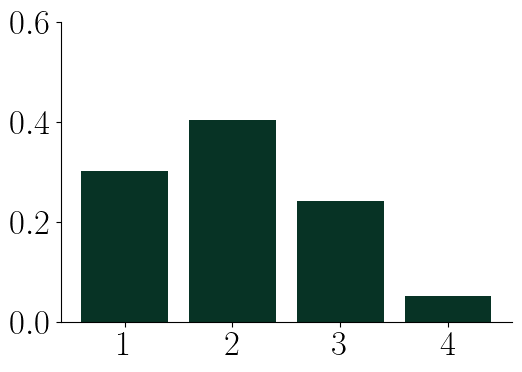

In [ ]:
plt.figure(figsize=(5.5, 4))

plt.bar(levels_stats["depth"], height=levels_stats["share"], color=DEFAULT_COLOR)

plt.yticks([0, 0.2, 0.4, 0.6])
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)

# plt.ylabel('Depth')
# plt.xlabel('Share')
plt.tight_layout()

plt.savefig(EXPORT_PATH / "depth_share.pdf", dpi=600, format="pdf")

### b) Exploited Depth

In [ ]:
occurrences_df = pd.read_pickle(PREPROCESSED_DATA_DECISIONS / 'matched_numerical_ids.pkl')
occurrences_df.head()

,Unnamed: 0,court,panel,decision,paragraph,pos,semantical_id,start,end,item,level,type,UUID
0,0,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_15,0,markeng_8_2_1,292.0,308.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
1,1,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_22,0,markeng_8_2_1,37.0,53.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
2,3,BPatG,BPatG_25. Senat,25 W (pat) 216/09,25 W (pat) 216/09_3,0,markeng_54_2,96.0,114.0,markeng_54_2,2,0,242215549959440275685037571880796361276
3,4,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_21,1,markeng_8_2_1,371.0,387.0,markeng_8_2_1,3,0,42064170535519776492744549313932832938
4,5,BPatG,BPatG_25. Senat,25 W (pat) 508/19,25 W (pat) 508/19_21,0,markeng_64_6,9.0,32.0,markeng_64_6,2,0,317653909489634983075549076632237719954


In [ ]:
full_df = pd.merge(
    occurrences_df, levels_df, left_on='semantical_id', right_on='sem_id'
)
full_df.columns

Index(['Unnamed: 0', 'court', 'panel', 'decision', 'paragraph', 'pos',
       'semantical_id', 'start', 'end', 'item', 'level_x', 'type', 'UUID',
       'sem_id', 'level_y', 'levels_below_min', 'relative_min',
       'levels_below_max', 'relative_max'],
      dtype='object')

In [ ]:
full_df["lowest_res"] = full_df['levels_below_min'] == 0

In [ ]:
agg_df = full_df[["lowest_res", "level_y"]].groupby("level_y").aggregate(["count", "sum"])
agg_df.columns = ['count', "sum_lowest_res"]
total = agg_df["count"].sum()
agg_df["count_scaled"] = agg_df["count"] / total
agg_df["sum_lowest_res_scaled"] = agg_df["sum_lowest_res"] / total
agg_df

,count,sum_lowest_res,count_scaled,sum_lowest_res_scaled
level_y,,,,
1,493516,184142,0.292872,0.109277
2,979840,875229,0.581476,0.519396
3,206466,200553,0.122525,0.119016
4,5268,5268,0.003126,0.003126


/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_33798/2124856030.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  bar2 = sns.barplot(x="level_y", y=count_col, data=agg_df, estimator=sum, ci=None, color=HIGHLIGHT_COLOR_LIGHT)
/var/folders/8k/r3s46h0143vflzq6wy9_001r0000gp/T/ipykernel_33798/2124856030.py:11: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  bar2 = sns.barplot(x="level_y", y=sum_lowest_res, data=agg_df, estimator=sum, ci=None, color=DEFAULT_COLOR)


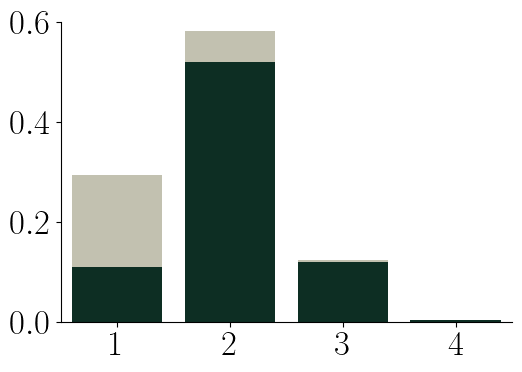

In [ ]:

plt.figure(figsize=(5.5, 4))
scaled = True # a prior graphics showed the absolute numbers

count_col = 'count' if not scaled else 'count_scaled'
sum_lowest_res = 'sum_lowest_res' if not scaled else 'sum_lowest_res_scaled'


bar2 = sns.barplot(x="level_y", y=count_col, data=agg_df, estimator=sum, ci=None, color=HIGHLIGHT_COLOR_LIGHT)


bar2 = sns.barplot(x="level_y", y=sum_lowest_res, data=agg_df, estimator=sum, ci=None, color=DEFAULT_COLOR)



#plt.xlabel("Section Level", fontsize=16)
#plt.ylabel("Number of actual References", fontsize=16)
#plt.yticks(fontsize=14)
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)

if not scaled:
    ax = bar2
    ax.ticklabel_format(style='sci', axis='y', scilimits=(6,6))
    ax.yaxis.get_offset_text().set_fontsize(35)

upperlim = .7 if scaled else 1
plt.yticks(np.arange(0, upperlim, 0.2))
plt.ylim(0,0.6)
plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.savefig(EXPORT_PATH / "reference_levels.pdf", dpi=600,)

top_bar = mpatches.Patch(color=DEFAULT_COLOR, label="Lowest possible\nreference level")
bottom_bar = mpatches.Patch(color=HIGHLIGHT_COLOR_LIGHT, label="Higher-level reference")

fig_legend = plt.figure(figsize=(6, 1.5))
fig_legend.legend(handles=[top_bar, bottom_bar], fontsize=30, loc='center')
fig_legend.tight_layout()
fig_legend.savefig(EXPORT_PATH / "reference_levels_legend.pdf", dpi=600, transparent=True)
plt.close(fig_legend)